**Import library**

In [12]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from wordcloud import WordCloud

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn import metrics
from scipy.cluster.hierarchy import dendrogram, linkage

In [13]:
# Membaca data hasil preprocessing
df = pd.read_csv('quanta_physics_preprocessing.csv')

# Memastikan kolom teks tersedia
if 'Processed_text' not in df.columns:
    raise ValueError("Kolom 'Processed_text' tidak ditemukan. Periksa nama kolom pada dataset.")

# Menghapus teks kosong/NA dan merapikan index
df = df.dropna(subset=['Processed_text']).reset_index(drop=True)
df['Processed_text'] = df['Processed_text'].astype(str).str.strip()
df = df[df['Processed_text'] != ''].reset_index(drop=True)

df_pre = df['Processed_text']
print('Jumlah artikel:', len(df))
display(df[['Title', 'Processed_text']].head())

Jumlah artikel: 775


,Title,Processed_text
0,Gravity Seems Holographic. What Does That Mean...,biggest breakthrough modern theoretical physic...
1,"Biology Might Not Be Quantum, but Its Math Is ...",scientist history trying failing link biology ...
2,Where Does the Quantum World End and Ours Begin?,jonathan halliwell explains quantum decoherenc...
3,Black Holes or Black Hole Stars? Astronomers S...,james webb space telescope spot mysterious lit...
4,"In Hilbert Space, All Things Are Quantumly Pos...",explore quantum phenomenon must leave familiar...


**Feature Engineering dengan TF-IDF**

In [14]:
vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(df_pre)

print('Ukuran matriks TF-IDF:', X.shape)
print('Jumlah fitur/kata unik:', len(vectorizer.get_feature_names_out()))

Ukuran matriks TF-IDF: (775, 3229)
Jumlah fitur/kata unik: 3229


**K-Means – Elbow Method**



Nilai k: [1, 2, 3, 4, 5, 6]
Nilai inertia: [762.965, 757.1044, 752.3949, 750.1917, 746.5328, 745.2241]


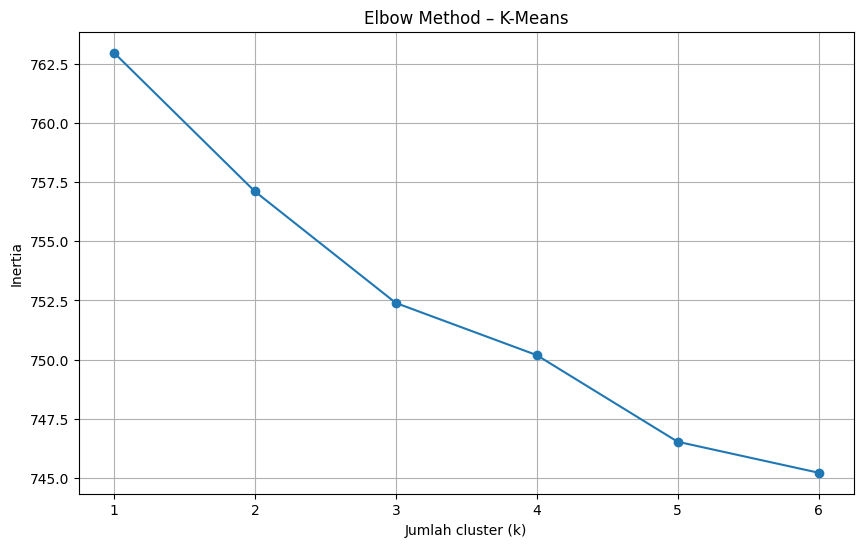

In [15]:
k = range(1, 7)
inertia = []

for i in k:
    km_model = KMeans(n_clusters=i, random_state=10, n_init=10)
    km_model.fit(X)
    inertia.append(km_model.inertia_)

print('Nilai k:', list(k))
print('Nilai inertia:', [round(value, 4) for value in inertia])

plt.figure(figsize=(10, 6))
plt.plot(list(k), inertia, marker='o')
plt.xlabel('Jumlah cluster (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method – K-Means')
plt.xticks(list(k))
plt.grid(True)
plt.show()

**K-Means dengan 4 cluster**

In [16]:
n_clusters = 4

kM = KMeans(n_clusters=n_clusters, random_state=10, n_init=10)
kM.fit(X)

df['Kmeans_label'] = kM.labels_
print('Jumlah artikel pada setiap cluster K-Means:')
display(df['Kmeans_label'].value_counts().sort_index().rename('Jumlah artikel').to_frame())
display(df[['Title', 'Kmeans_label']].head())

Jumlah artikel pada setiap cluster K-Means:


,Jumlah artikel
Kmeans_label,
0,244
1,242
2,214
3,75


,Title,Kmeans_label
0,Gravity Seems Holographic. What Does That Mean...,2
1,"Biology Might Not Be Quantum, but Its Math Is ...",2
2,Where Does the Quantum World End and Ours Begin?,2
3,Black Holes or Black Hole Stars? Astronomers S...,1
4,"In Hilbert Space, All Things Are Quantumly Pos...",2


**Silhouette Score – K-Means**

In [17]:
labels = kM.labels_
silhouette_kmeans = metrics.silhouette_score(X, labels, metric='euclidean')
print('Silhouette Score K-Means:', round(silhouette_kmeans, 4))

Silhouette Score K-Means: 0.0062


**Kata kunci utama setiap cluster K-Means**

In [18]:
terms = vectorizer.get_feature_names_out()

for c in range(n_clusters):
    cluster_matrix = X[df['Kmeans_label'].to_numpy() == c]
    mean_tfidf = np.asarray(cluster_matrix.mean(axis=0)).ravel()
    top_indices = mean_tfidf.argsort()[::-1][:10]
    print(f"Cluster {c}:", ', '.join(terms[top_indices]))

Cluster 0: new, universe, particle, physicist, matter, dark, could, way, energy, experiment
Cluster 1: astronomer, earth, star, scientist, planet, first, system, life, galaxy, researcher
Cluster 2: quantum, theory, physic, physicist, time, gravity, experiment, space, mechanic, world
Cluster 3: hole, black, supermassive, gravitational, physicist, new, wave, galaxy, center, astrophysicist


**Word Cloud – K-Means**

K-Means – Cluster 0


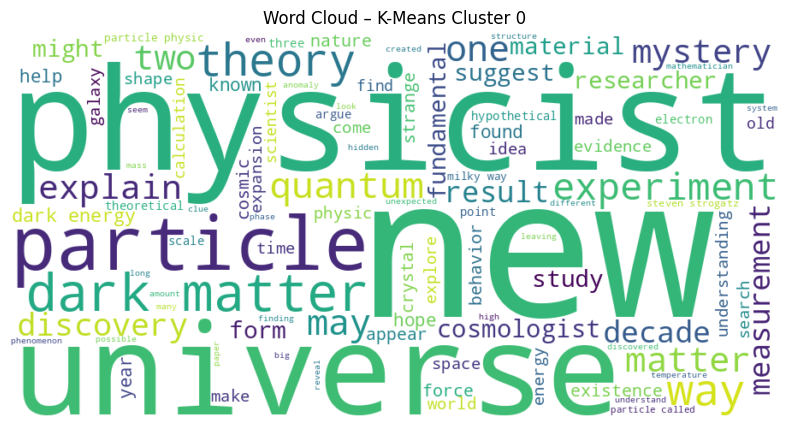

K-Means – Cluster 1


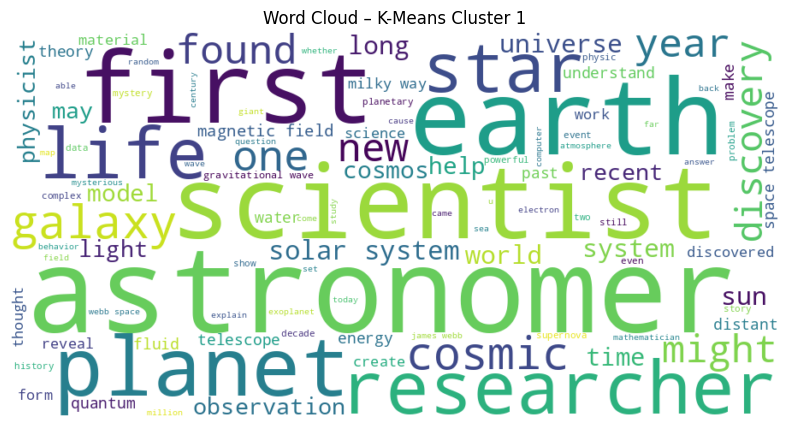

K-Means – Cluster 2


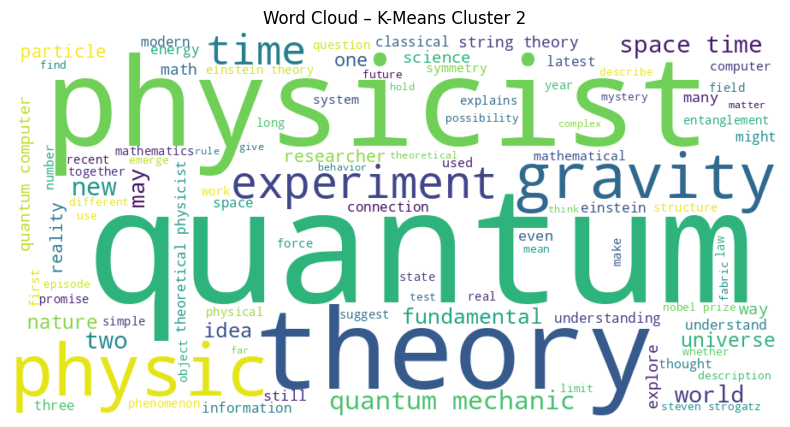

K-Means – Cluster 3


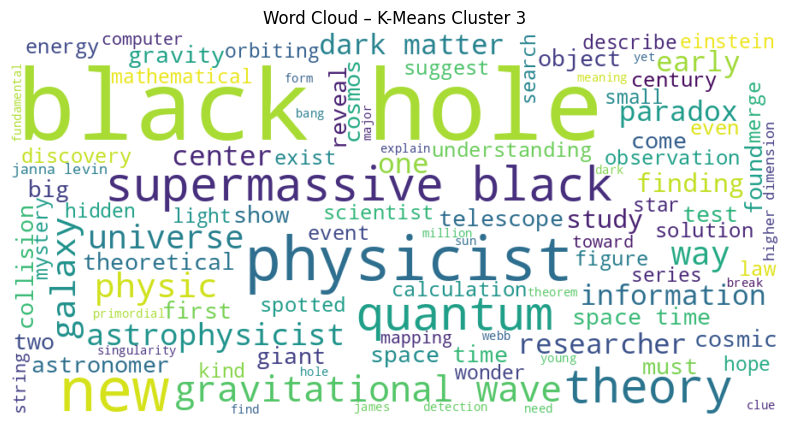

In [19]:
for c in sorted(df['Kmeans_label'].unique()):
    print(f'K-Means – Cluster {c}')
    df_c = df[df['Kmeans_label'] == c]
    long_string = ' '.join(df_c['Processed_text'].astype(str).tolist())

    wordcloud = WordCloud(
        background_color='white',
        max_words=100,
        width=900,
        height=450,
        contour_width=0
    ).generate(long_string)

    plt.figure(figsize=(12, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    plt.title(f'Word Cloud – K-Means Cluster {c}')
    plt.show()

**Hierarchical Clustering – Dendrogram**

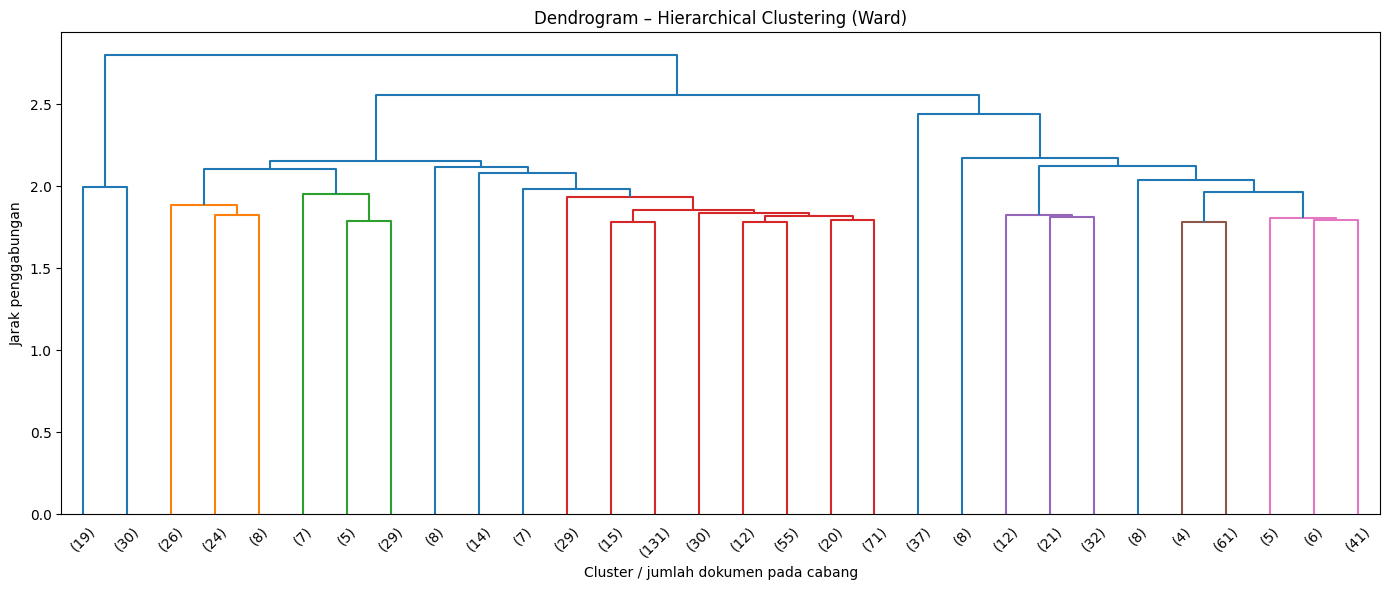

In [20]:
# Ward linkage membutuhkan array dense dengan jarak Euclidean
X_dense = X.toarray()
linkage_data = linkage(X_dense, method='ward', metric='euclidean')

plt.figure(figsize=(14, 6))
dendrogram(
    linkage_data,
    truncate_mode='lastp',
    p=30,
    show_leaf_counts=True
)
plt.title('Dendrogram – Hierarchical Clustering (Ward)')
plt.xlabel('Cluster / jumlah dokumen pada cabang')
plt.ylabel('Jarak penggabungan')
plt.tight_layout()
plt.show()

**Hierarchical Clustering dengan Ward**

In [21]:
hierarchical_cluster = AgglomerativeClustering(
    n_clusters=n_clusters,
    linkage='ward'
)

hierarchical_cluster.fit(X_dense)
df['Ward_label'] = hierarchical_cluster.labels_

print('Jumlah artikel pada setiap cluster Ward:')
display(df['Ward_label'].value_counts().sort_index().rename('Jumlah artikel').to_frame())
display(df[['Title', 'Kmeans_label', 'Ward_label']].head())

Jumlah artikel pada setiap cluster Ward:


,Jumlah artikel
Ward_label,
0,198
1,49
2,491
3,37


,Title,Kmeans_label,Ward_label
0,Gravity Seems Holographic. What Does That Mean...,2,2
1,"Biology Might Not Be Quantum, but Its Math Is ...",2,2
2,Where Does the Quantum World End and Ours Begin?,2,2
3,Black Holes or Black Hole Stars? Astronomers S...,1,0
4,"In Hilbert Space, All Things Are Quantumly Pos...",2,2


**Silhouette Score – Hierarchical**

In [22]:
labels_ward = df['Ward_label'].to_numpy()
silhouette_ward = metrics.silhouette_score(X, labels_ward, metric='euclidean')
print('Silhouette Score Hierarchical (Ward):', round(silhouette_ward, 4))

comparison = pd.DataFrame({
    'Metode': ['K-Means', 'Hierarchical (Ward)'],
    'Jumlah cluster': [n_clusters, n_clusters],
    'Silhouette Score': [silhouette_kmeans, silhouette_ward]
})
display(comparison)

Silhouette Score Hierarchical (Ward): 0.0022


,Metode,Jumlah cluster,Silhouette Score
0,K-Means,4,0.006177
1,Hierarchical (Ward),4,0.002229


**Word Cloud – Hierarchical Clustering**

Hierarchical Ward – Cluster 0


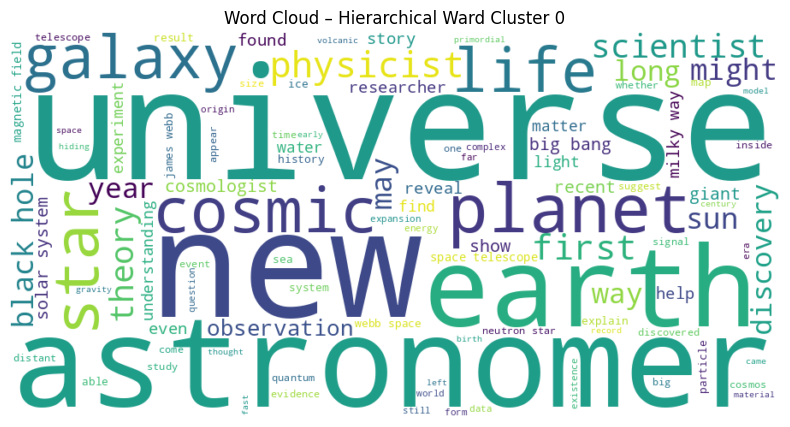

Hierarchical Ward – Cluster 1


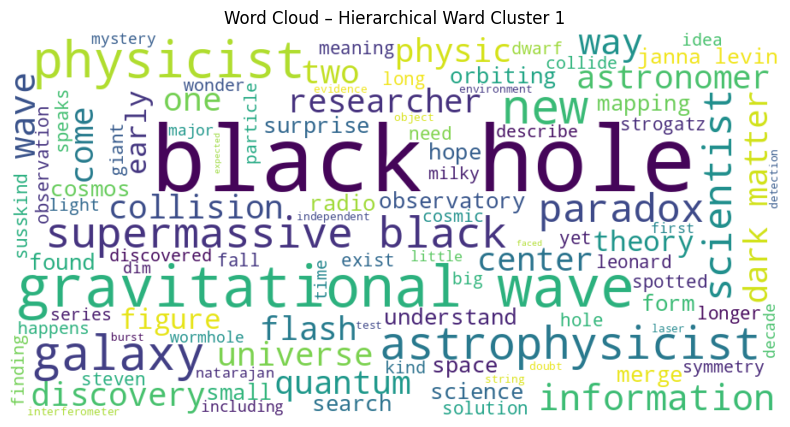

Hierarchical Ward – Cluster 2


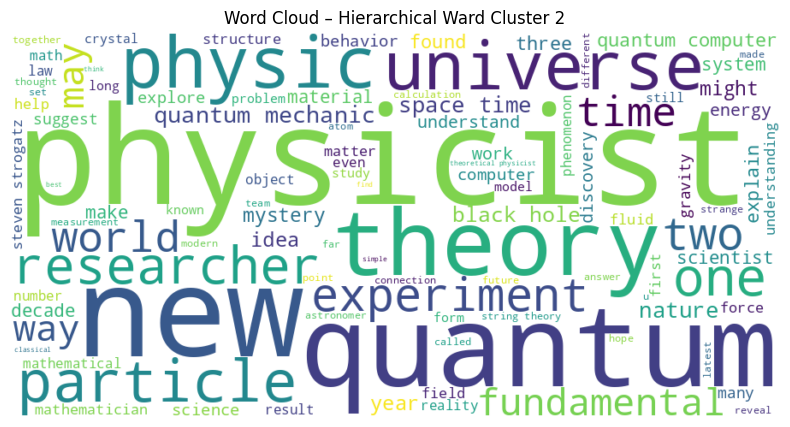

Hierarchical Ward – Cluster 3


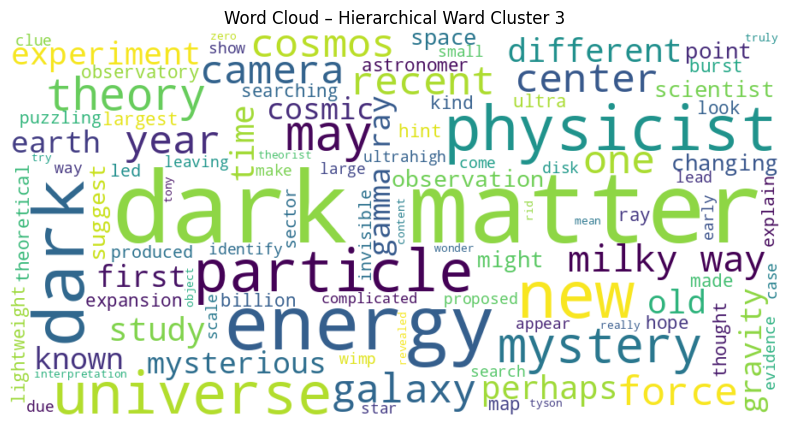

In [23]:
for c in sorted(df['Ward_label'].unique()):
    print(f'Hierarchical Ward – Cluster {c}')
    df_c = df[df['Ward_label'] == c]
    long_string = ' '.join(df_c['Processed_text'].astype(str).tolist())

    wordcloud = WordCloud(
        background_color='white',
        max_words=100,
        width=900,
        height=450,
        contour_width=0
    ).generate(long_string)

    plt.figure(figsize=(12, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    plt.title(f'Word Cloud – Hierarchical Ward Cluster {c}')
    plt.show()

**Menyimpan hasil clustering**

In [24]:
output_file = 'quanta_physics_text_clustering_results.csv'
df.to_csv(output_file, index=False)
print('Hasil disimpan ke:', output_file)


Hasil disimpan ke: quanta_physics_text_clustering_results.csv
